# MITRE ATT&CK Code Identification - LLM Benchmarking

This notebook creates a labeled test dataset from multiple TSV files and benchmarks various Groq LLM models on their ability to identify MITRE ATT&CK technique codes from cybersecurity descriptions.

## Overview
- **Goal**: Evaluate LLM models' capability to predict MITRE ATT&CK codes from threat descriptions
- **Dataset**: Random samples from procedures, expert, TRAM, and derived procedures datasets
- **Models**: Multiple LLMs (Llama, Mixtral, Gemma models)
- **Evaluation**: Accuracy, F1-score, exact match, and partial match metrics

In [1]:
# Core Data Processing Libraries
import pandas as pd
import numpy as np
import glob
import random
import os
import json
import ast
import re
import warnings
warnings.filterwarnings('ignore')

print("Core libraries imported successfully!")

Core libraries imported successfully!


In [2]:
# Visualization and Machine Learning Libraries
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from typing import List, Dict, Any

print("Visualization and ML libraries imported successfully!")

Visualization and ML libraries imported successfully!


In [3]:
# !pip install groq
# !pip install anthropic
# !pip install openai
# !pip install google-generativeai

In [4]:
# API and Timing Libraries
import time
from groq import Groq
from anthropic import Anthropic
import openai
from openai import OpenAI

print("API and timing libraries imported successfully!")

API and timing libraries imported successfully!


In [5]:
# Set Random Seeds for Reproducibility
random.seed(120)
np.random.seed(120)

print("Random seeds set for reproducibility!")
print(f"Current working directory: {os.getcwd()}")

Random seeds set for reproducibility!
Current working directory: c:\Lobna\STAGE_WEVIOO\Project\misc\benchmarks\cti-to-mitre-llm\benchmark


In [6]:
!git clone https://github.com/tumeteor/mitre-ttp-mapping

fatal: destination path 'mitre-ttp-mapping' already exists and is not an empty directory.


In [7]:
# File Paths and Dataset Configuration
BASE_PATH = "mitre-ttp-mapping/datasets"
SAMPLES_PER_FILE = 14  # Number of samples to take from each file
OUTPUT_CSV = "benchmark_dataset.csv"

# Dataset directories
DATASET_DIRS = {
    'procedures': os.path.join(BASE_PATH, 'procedures'),
    'expert': os.path.join(BASE_PATH, 'expert'),
    'tram': os.path.join(BASE_PATH, 'tram'),
    'derived_procedures': os.path.join(BASE_PATH, 'derived_procedures')
}

print("Dataset configuration set!")
print(f"Base path: {BASE_PATH}")
print(f"Samples per file: {SAMPLES_PER_FILE}")
print(f"Dataset directories: {list(DATASET_DIRS.keys())}")

Dataset configuration set!
Base path: mitre-ttp-mapping/datasets
Samples per file: 14
Dataset directories: ['procedures', 'expert', 'tram', 'derived_procedures']


In [8]:
# Groq models to test
GROQ_MODELS = [
    # "gemma2-9b-it",          # Successor to gemma-7b
    # "meta-llama/llama-4-maverick-17b-128e-instruct",  # Great results
    # "meta-llama/llama-4-scout-17b-16e-instruct",      # Retry if 503 clears
    # "qwen/qwen3-32b",         # Large multilingual, performance varies
    "mistral-saba-24b",
    # "llama3-70b-8192",
    # "deepseek-r1-distill-llama-70b",
    # "llama-3.3-70b-versatile"
]
ANTHROPIC_MODELS = [
    # "claude-opus-4-20250514",
    # "claude-sonnet-4-20250514",
    # "claude-3-7-sonnet-20250219",
    # 	"claude-3-5-sonnet-20241022",
    # "claude-3-5-haiku-20241022"
]

GEMINI_MODELS = [
    # "gemini-1.5-pro",
    "gemini-2.5-flash",
    "gemini-2.0-flash",
    "gemini-1.5-flash",
    "gemini-2.5-flash-lite-preview-06-17"
]

print(f"Groq models to test: {len(GROQ_MODELS)}")
print(f"Anthropic models to test: {len(ANTHROPIC_MODELS)}")
print(f"Gemini models to test: {len(GEMINI_MODELS)}")

Groq models to test: 1
Anthropic models to test: 0
Gemini models to test: 4


## Dataset Loading and Preparation

This section loads the TSV files from different dataset categories and prepares them for sampling.

In [9]:
# TSV File Loading Function
def load_tsv_files():
    """Load all TSV files from the dataset directories"""
    all_files = {}

    for category, directory in DATASET_DIRS.items():
        tsv_files = glob.glob(os.path.join(directory, "*.tsv"))
        print(f"\n{category.upper()} directory: {directory}")
        print(f"Found {len(tsv_files)} TSV files:")

        category_data = {}
        for file_path in tsv_files:
            file_name = os.path.basename(file_path)
            print(f"  - {file_name}")

            try:
                # Load TSV file
                df = pd.read_csv(file_path, sep='\t', encoding='utf-8')
                print(f"    Shape: {df.shape}")
                print(f"    Columns: {list(df.columns)}")
                category_data[file_name] = df

                # Show sample
                if len(df) > 0:
                    print(f"    Sample text: {df.iloc[0]['text1'][:100]}...")
                    print(f"    Sample labels: {df.iloc[0]['labels']}")

            except Exception as e:
                print(f"    Error loading {file_name}: {e}")

        all_files[category] = category_data

    return all_files

print("TSV file loading function defined!")

TSV file loading function defined!


In [10]:
# Execute: Load All TSV Files
all_data = load_tsv_files()

print(f"\nSummary:")
print(f"Total categories loaded: {len(all_data)}")
total_files = sum(len(files) for files in all_data.values())
print(f"Total files loaded: {total_files}")


PROCEDURES directory: mitre-ttp-mapping/datasets\procedures
Found 3 TSV files:
  - procedure_dev.tsv
    Shape: (1469, 2)
    Columns: ['text1', 'labels']
    Sample text: APT28 added "junk data" to each encoded string, preventing trivial decoding without knowledge of the...
    Sample labels: ['T1001.001']
  - procedure_test.tsv
    Shape: (1767, 2)
    Columns: ['text1', 'labels']
    Sample text: POWERSTATS encoded C2 traffic with base64....
    Sample labels: ['T1001', 'T1132.001']
  - procedure_train.tsv
    Shape: (8487, 2)
    Columns: ['text1', 'labels']
    Sample text: During Operation Wocao, threat actors encrypted IP addresses used for "Agent" proxy hops with RC4....
    Sample labels: ['T1001']

EXPERT directory: mitre-ttp-mapping/datasets\expert
Found 3 TSV files:
  - expert_dev.tsv
    Shape: (69, 2)
    Columns: ['text1', 'labels']
    Sample text: For the discovery phase, the Carbanak and FIN7 campaigns gain more knowledge about the system by gat...
    Sample labels:

## Data Sampling

Now we'll randomly sample a specified number of rows from each loaded file to create our benchmark dataset.

In [11]:
# Data Sampling Function
def sample_data_from_files(all_data, samples_per_file=SAMPLES_PER_FILE):
    """Randomly sample rows from each TSV file"""
    sampled_data = []

    for category, files in all_data.items():
        print(f"\nSampling from {category.upper()} files:")

        for filename, df in files.items():
            if len(df) == 0:
                print(f"  {filename}: Empty file, skipping")
                continue

            # Determine sample size
            sample_size = min(samples_per_file, len(df))

            # Random sampling
            sampled_df = df.sample(n=sample_size, random_state=42).copy()

            # Add metadata
            sampled_df['source_category'] = category
            sampled_df['source_file'] = filename

            sampled_data.append(sampled_df)
            print(f"  {filename}: Sampled {sample_size} rows from {len(df)} total")

    return sampled_data

print("Data sampling function defined!")

Data sampling function defined!


In [12]:
# Combine and Shuffle Function Definition
def combine_and_shuffle_data(sampled_datasets):
    """Combine all sampled datasets and shuffle"""
    # Combine all dataframes
    combined_df = pd.concat(sampled_datasets, ignore_index=True)

    # Shuffle the data
    shuffled_df = combined_df.sample(frac=1, random_state=42).reset_index(drop=True)

    print(f"Combined dataset shape: {shuffled_df.shape}")
    print(f"Columns: {list(shuffled_df.columns)}")

    # Show distribution by source
    print("\nDistribution by source category:")
    print(shuffled_df['source_category'].value_counts())

    print("\nDistribution by source file:")
    print(shuffled_df['source_file'].value_counts())

    return shuffled_df

print("Data combination and shuffling function defined!")

Data combination and shuffling function defined!


In [13]:
# Execute: Sample Data from All Files
sampled_datasets = sample_data_from_files(all_data, SAMPLES_PER_FILE)

print(f"\nTotal sampled datasets: {len(sampled_datasets)}")
total_samples = sum(len(df) for df in sampled_datasets)
print(f"Total samples collected: {total_samples}")


Sampling from PROCEDURES files:
  procedure_dev.tsv: Sampled 14 rows from 1469 total
  procedure_test.tsv: Sampled 14 rows from 1767 total
  procedure_train.tsv: Sampled 14 rows from 8487 total

Sampling from EXPERT files:
  expert_dev.tsv: Sampled 14 rows from 69 total
  expert_test.tsv: Sampled 14 rows from 157 total
  expert_train.tsv: Sampled 14 rows from 471 total

Sampling from TRAM files:
  tram_dev.tsv: Sampled 14 rows from 604 total
  tram_test.tsv: Sampled 14 rows from 725 total
  tram_train.tsv: Sampled 14 rows from 3468 total

Sampling from DERIVED_PROCEDURES files:
  derived_procedure_dev.tsv: Sampled 14 rows from 488 total
  derived_procedure_test.tsv: Sampled 14 rows from 521 total
  derived_procedure_train.tsv: Sampled 14 rows from 2510 total

Total sampled datasets: 12
Total samples collected: 168


In [14]:
# Execute: Combine and Shuffle Sampled Data
benchmark_dataset = combine_and_shuffle_data(sampled_datasets)

Combined dataset shape: (168, 4)
Columns: ['text1', 'labels', 'source_category', 'source_file']

Distribution by source category:
source_category
derived_procedures    42
procedures            42
tram                  42
expert                42
Name: count, dtype: int64

Distribution by source file:
source_file
derived_procedure_dev.tsv      14
procedure_train.tsv            14
tram_train.tsv                 14
derived_procedure_test.tsv     14
derived_procedure_train.tsv    14
expert_dev.tsv                 14
tram_test.tsv                  14
expert_test.tsv                14
procedure_test.tsv             14
tram_dev.tsv                   14
expert_train.tsv               14
procedure_dev.tsv              14
Name: count, dtype: int64


In [15]:
# Preview the dataset
print("\nFirst 5 rows of the benchmark dataset:")
print(benchmark_dataset[['text1', 'labels', 'source_category']].head())

print("\nSample of different label types:")
unique_labels = benchmark_dataset['labels'].unique()[:10]
for i, label in enumerate(unique_labels):
    print(f"{i+1}. {label}")


First 5 rows of the benchmark dataset:
                                               text1                  labels  \
0  SDBbot RAT has been observed in Hive0065 attac...      ['T1140', 'T1125']   
1  CookieMiner has used Google Chrome's decryptio...               ['T1140']   
2  We were able to brute force the actor-provided...               ['T1110']   
3  Remsec is capable of using ICMP, TCP, and UDP ...               ['T1095']   
4  The following file paths can be used to detect...  ['T1083', 'T1505.003']   

      source_category  
0  derived_procedures  
1          procedures  
2                tram  
3          procedures  
4  derived_procedures  

Sample of different label types:
1. ['T1140', 'T1125']
2. ['T1140']
3. ['T1110']
4. ['T1095']
5. ['T1083', 'T1505.003']
6. ['T1027']
7. ['T1204.002', 'T1204.001']
8. ['T1588.001', 'T1583.002']
9. ['T1033']
10. ['T1587.001', 'T1622']


In [16]:
# Label Processing Function Definition
def process_labels(df):
    """Process and clean the labels column"""
    def parse_label_string(label_str):
        """Parse label string to extract list of MITRE codes"""
        try:
            # Use ast.literal_eval to safely parse the string representation of the list
            parsed_labels = ast.literal_eval(label_str)
            if isinstance(parsed_labels, list):
                return parsed_labels
            else:
                return [str(parsed_labels)]
        except:
            # Fallback: try to extract T-codes using regex
            t_codes = re.findall(r'T\d+(?:\.\d+)*', str(label_str))
            return t_codes if t_codes else [label_str]

    # Process labels
    df_processed = df.copy()
    df_processed['labels_parsed'] = df_processed['labels'].apply(parse_label_string)

    # Create a flat version for easier analysis
    df_processed['labels_count'] = df_processed['labels_parsed'].apply(len)
    df_processed['primary_label'] = df_processed['labels_parsed'].apply(lambda x: x[0] if x else 'Unknown')

    return df_processed

print("Label processing function defined!")

Label processing function defined!


In [17]:
# Execute: Process Labels in Dataset
benchmark_dataset_processed = process_labels(benchmark_dataset)

In [18]:
# Display label statistics
print("Label Statistics:")
print(f"Total samples: {len(benchmark_dataset_processed)}")
print(f"Average labels per sample: {benchmark_dataset_processed['labels_count'].mean():.2f}")
print(f"Max labels in a sample: {benchmark_dataset_processed['labels_count'].max()}")
print(f"Min labels in a sample: {benchmark_dataset_processed['labels_count'].min()}")

print("\nMost common primary labels:")
print(benchmark_dataset_processed['primary_label'].value_counts().head(10))

Label Statistics:
Total samples: 168
Average labels per sample: 1.39
Max labels in a sample: 8
Min labels in a sample: 1

Most common primary labels:
primary_label
T1027        8
T1033        7
T1082        6
T1083        5
T1588.001    5
T1106        5
T1547.001    4
T1071.001    4
T1057        4
T1105        4
Name: count, dtype: int64


In [19]:
# Execute: Export Dataset to CSV
benchmark_dataset_processed.to_csv(OUTPUT_CSV, index=False)
print(f"Dataset exported to: {OUTPUT_CSV}")
print(f"Final dataset shape: {benchmark_dataset_processed.shape}")
print(f"Columns exported: {list(benchmark_dataset_processed.columns)}")

Dataset exported to: benchmark_dataset.csv
Final dataset shape: (168, 7)
Columns exported: ['text1', 'labels', 'source_category', 'source_file', 'labels_parsed', 'labels_count', 'primary_label']


## LLM Benchmarking Setup

Now that we have our labeled dataset, let's set up the benchmarking infrastructure to test multiple Groq LLM models on their ability to identify MITRE ATT&CK codes.

In [20]:
# Groq API Key Configuration
from dotenv import load_dotenv
import os

# Load environment variables from .env file
load_dotenv()

# Now access your API keys
GROQ_API_KEY = os.getenv("GROQ_API_KEY")

# Initialize Groq client
groq_client = Groq(api_key=GROQ_API_KEY)

print("Groq API configuration loaded!")

Groq API configuration loaded!


In [21]:
# Initialize Anthropic client
ANTHROPIC_API_KEY = os.getenv("ANTHROPIC_API_KEY")
anthropic_client = Anthropic(api_key=ANTHROPIC_API_KEY)

print("Anthropic API configuration loaded!")

Anthropic API configuration loaded!


In [22]:
# Initialize Gemini client
import google.generativeai as genai
from typing import List

GOOGLE_API_KEY = os.getenv("GOOGLE_API_KEY")
genai.configure(api_key=GOOGLE_API_KEY)

print("Google API configuration loaded!")

Google API configuration loaded!


In [23]:
# def create_prompt(description: str) -> str:
#     """Create a structured prompt for MITRE ATT&CK code identification"""
#     prompt = f"""You are a cybersecurity expert specialized in the MITRE ATT&CK framework. Your task is to analyze a Cyber Threat Intelligence (CTI) description and identify the most relevant MITRE ATT&CK technique(s) based on the described behaviors.

# Task Instructions:
# Input Analysis: Analyze the provided CTI threat description to extract Indicators of Compromise (IoCs), attacker behaviors, and attack stages.
# MITRE ATT&CK Mapping: Map these behaviors to the corresponding MITRE ATT&CK techniques (format: T#### or T####.### for sub-techniques).
# Few-Shot Examples: Use the examples below as guidance for accurate mapping.
# Multiple Techniques Handling: If multiple techniques apply, return all that are relevant. Prioritize specific sub-techniques over general ones when applicable.
# Ambiguity Management: If unsure, choose the most likely technique based on semantic similarity to known MITRE descriptions. Avoid generic or overly broad techniques.
# Validation: Ensure each identified technique aligns logically with the attack phase described and is compatible with SIEM/SOAR systems.
# Output Format: Return only a JSON list of MITRE ATT&CK codes without additional explanations.

# Few-Shot Examples:
# Example 1
# Description: "The adversary uses PowerShell to execute malicious payloads."
# Identified Techniques: ["T1059", "T1484.001"]

# Example 2
# Description: "Malware collects system information using built-in OS tools."
# Identified Techniques: ["T1082"]

# Example 3
# Description: "Data is exfiltrated through DNS requests to an external domain."
# Identified Techniques: ["T1048", "T1048.003"]

# Threat Description:
# "{description}"

# Response Format:
# ["T####", "T####.###", ...]"""
#     return prompt

In [24]:
# def create_prompt(description: str) -> str:
#     """Create a structured prompt for MITRE ATT&CK code identification"""
#     prompt = f"""You are an experienced cybersecurity threat analyst with deep expertise in the MITRE ATT&CK framework and operational threat intelligence. Your role is to systematically analyze Cyber Threat Intelligence (CTI) reports and accurately map observed behaviors to specific MITRE ATT&CK techniques, following the same analytical process used by senior SOC analysts and threat hunters.

# ## Analysis Framework

# ### Step 1: Threat Behavior Extraction
# - **Identify Observable Actions**: Extract specific attacker behaviors, tools, and methods
# - **Map Attack Progression**: Determine the attack lifecycle phase (initial access, persistence, etc.)
# - **Extract Technical Indicators**: Note file types, network protocols, system commands, and artifacts

# ### Step 2: MITRE ATT&CK Technique Mapping
# - **Primary Technique Selection**: Choose the most specific applicable technique
# - **Sub-technique Prioritization**: Prefer specific sub-techniques (T####.###) over parent techniques when applicable
# - **Multiple Technique Handling**: Include all relevant techniques that match the described behavior
# - **Confidence Assessment**: Prioritize techniques with clear behavioral alignment

# ### Step 3: Analytical Reasoning (Chain-of-Thought)
# For each technique identification, consider:
# 1. **Behavioral Match**: Does the described activity directly align with the MITRE technique definition?
# 2. **Attack Phase Alignment**: Is the technique consistent with the attack stage being described?
# 3. **Technical Feasibility**: Are the tools/methods mentioned capable of executing this technique?
# 4. **Contextual Relevance**: Does the technique make sense within the broader attack narrative?

# ## Few-Shot Learning Examples

# ### Example 1: Command Line Execution
# **CTI Description**: "The threat actor deployed a PowerShell script that downloaded additional payloads from a remote server using Invoke-WebRequest and executed them in memory to avoid disk-based detection."

# **Analytical Reasoning**:
# - PowerShell usage indicates command and scripting interpreter execution → T1059.001
# - Remote payload download suggests ingress tool transfer → T1105
# - In-memory execution implies defense evasion techniques

# **Identified Techniques**: ["T1059.001", "T1105"]

# ### Example 2: Multi-Stage Persistence
# **CTI Description**: "After gaining initial access, the malware created a scheduled task named 'SystemUpdate' that executed every hour, while also modifying the Windows registry to establish persistence through the Run key."

# **Analytical Reasoning**:
# - Scheduled task creation for persistence → T1053.005
# - Registry Run key modification for persistence → T1547.001
# - Multiple persistence mechanisms indicate sophisticated approach

# **Identified Techniques**: ["T1053.005", "T1547.001"]

# ### Example 3: Data Collection and Exfiltration
# **CTI Description**: "The adversary used built-in Windows commands like 'systeminfo' and 'net user' to gather system and user account information, then compressed the collected data using WinRAR before uploading it to a cloud storage service."

# **Analytical Reasoning**:
# - System information gathering using built-in tools → T1082
# - User account discovery through 'net user' → T1087.001
# - Data compression for exfiltration → T1560.001
# - Cloud service exfiltration → T1567.002

# **Identified Techniques**: ["T1082", "T1087.001", "T1560.001", "T1567.002"]

# ### Example 4: Lateral Movement
# **CTI Description**: "Using stolen credentials, the attacker accessed additional systems via RDP connections and deployed tools through SMB file shares to propagate across the network."

# **Analytical Reasoning**:
# - Credential usage for access → T1078
# - RDP for lateral movement → T1021.001
# - SMB share usage for tool deployment → T1021.002

# **Identified Techniques**: ["T1078", "T1021.001", "T1021.002"]

# ## Output Format
# Return only a JSON list of MITRE ATT&CK technique codes without additional explanations.

# **Format**: `["T####", "T####.###", ...]`

# ### Quality Criteria
# - **Specificity**: Prefer sub-techniques over parent techniques when specific behaviors are described
# - **Completeness**: Include all techniques that have clear behavioral evidence
# - **Accuracy**: Ensure technique definitions align with described activities
# - **Operational Relevance**: Select techniques useful for detection and response activities

# ## Processing Instructions

# 1. **Read the entire CTI description** to understand the full attack context
# 2. **Extract key behavioral indicators** and technical details
# 3. **Apply analytical reasoning** to map behaviors to MITRE techniques
# 4. **Validate technique selections** against MITRE ATT&CK definitions
# 5. **Format output** according to specified JSON structure
# 6. **Review for completeness** and operational applicability

# ## Task Execution

# Analyze the following threat description and return only the JSON list of identified MITRE ATT&CK techniques:

# **Threat Description**: "{description}"
# """
#     return prompt

In [25]:
def create_prompt(description: str) -> str:
    """Create a structured prompt for MITRE ATT&CK code identification"""
    prompt = f"""You are an experienced cybersecurity threat analyst with deep expertise in the MITRE ATT&CK framework and operational threat intelligence. Your role is to systematically analyze Cyber Threat Intelligence (CTI) reports and accurately map observed behaviors to specific MITRE ATT&CK techniques, following the same analytical process used by senior SOC analysts and threat hunters.

## Analysis Framework

### Step 1: Threat Behavior Extraction
- **Identify Observable Actions**: Extract specific attacker behaviors, tools, and methods
- **Map Attack Progression**: Determine the attack lifecycle phase (initial access, persistence, etc.)
- **Extract Technical Indicators**: Note file types, network protocols, system commands, and artifacts

### Step 2: MITRE ATT&CK Technique Mapping
- **Primary Technique Selection**: Choose the most specific applicable technique
- **Sub-technique Prioritization**: Prefer specific sub-techniques (T####.###) over parent techniques when applicable
- **Multiple Technique Handling**: Include all relevant techniques that match the described behavior
- **Confidence Assessment**: Prioritize techniques with clear behavioral alignment

### Step 3: Analytical Reasoning (Chain-of-Thought)
For each technique identification, consider:
1. **Behavioral Match**: Does the described activity directly align with the MITRE technique definition?
2. **Attack Phase Alignment**: Is the technique consistent with the attack stage being described?
3. **Technical Feasibility**: Are the tools/methods mentioned capable of executing this technique?
4. **Contextual Relevance**: Does the technique make sense within the broader attack narrative?

## Few-Shot Learning Examples

### Example 1: Command Line Execution
**CTI Description**: "The threat actor deployed a PowerShell script that downloaded additional payloads from a remote server using Invoke-WebRequest and executed them in memory to avoid disk-based detection."

**Analytical Reasoning**:
- PowerShell usage indicates command and scripting interpreter execution → T1059.001
- Remote payload download suggests ingress tool transfer → T1105
- In-memory execution implies defense evasion techniques

**Identified Techniques**: ["T1059.001", "T1105"]

### Example 2: Multi-Stage Persistence
**CTI Description**: "After gaining initial access, the malware created a scheduled task named 'SystemUpdate' that executed every hour, while also modifying the Windows registry to establish persistence through the Run key."

**Analytical Reasoning**:
- Scheduled task creation for persistence → T1053.005
- Registry Run key modification for persistence → T1547.001
- Multiple persistence mechanisms indicate sophisticated approach

**Identified Techniques**: ["T1053.005", "T1547.001"]

### Example 3: Data Collection and Exfiltration
**CTI Description**: "The adversary used built-in Windows commands like 'systeminfo' and 'net user' to gather system and user account information, then compressed the collected data using WinRAR before uploading it to a cloud storage service."

**Analytical Reasoning**:
- System information gathering using built-in tools → T1082
- User account discovery through 'net user' → T1087.001
- Data compression for exfiltration → T1560.001
- Cloud service exfiltration → T1567.002

**Identified Techniques**: ["T1082", "T1087.001", "T1560.001", "T1567.002"]

### Example 4: Lateral Movement
**CTI Description**: "Using stolen credentials, the attacker accessed additional systems via RDP connections and deployed tools through SMB file shares to propagate across the network."

**Analytical Reasoning**:
- Credential usage for access → T1078
- RDP for lateral movement → T1021.001
- SMB share usage for tool deployment → T1021.002

**Identified Techniques**: ["T1078", "T1021.001", "T1021.002"]

### Example 5: What NOT to Do
CTI Description: "The security team noticed unusual network traffic patterns and some files were modified on multiple systems."

**Poor Analysis (Avoid This)**:
- Vague "unusual network traffic" mapped to overly broad techniques
- "Files modified" without context leading to generic file system techniques
- No specific attacker behaviors identified

**Incorrect Identified Techniques**: ["T1071", "T1005", "T1083"]
Why This is Wrong: These techniques don't match the vague description and lack specific behavioral evidence. The description provides insufficient technical details for accurate MITRE mapping.
**Correct Approach**: When descriptions are too vague or lack specific attacker behaviors, return an empty list: []

## Output Format
Return only a JSON list of MITRE ATT&CK technique codes without additional explanations.

**Format**: `["T####", "T####.###", ...]`

### Quality Criteria
- **Specificity**: Prefer sub-techniques over parent techniques when specific behaviors are described
- **Completeness**: Include all techniques that have clear behavioral evidence
- **Accuracy**: Ensure technique definitions align with described activities
- **Operational Relevance**: Select techniques useful for detection and response activities

## Processing Instructions

1. **Read the entire CTI description** to understand the full attack context
2. **Extract key behavioral indicators** and technical details
3. **Apply analytical reasoning** to map behaviors to MITRE techniques
4. **Validate technique selections** against MITRE ATT&CK definitions
5. **Format output** according to specified JSON structure
6. **Review for completeness** and operational applicability

## Task Execution

Analyze the following threat description and return only the JSON list of identified MITRE ATT&CK techniques:

**Threat Description**: "{description}"
"""
    return prompt

In [26]:
def parse_llm_response(response: str) -> List[str]:
    """Parse LLM response to extract MITRE codes"""
    try:
        # Try to parse as JSON first
        if response.strip().startswith('[') and response.strip().endswith(']'):
            codes = json.loads(response.strip())
            return [str(code) for code in codes]

        # Fallback: extract T-codes using regex
        t_codes = re.findall(r'T\d+(?:\.\d+)*', response)
        return t_codes

    except Exception as e:
        print(f"Error parsing response: {e}")
        print(f"Response: {response}")
        return []

print("Groq API setup complete!")

Groq API setup complete!


## Evaluation Metrics Setup

This section defines the evaluation functions that will be used to assess model performance on MITRE ATT&CK code identification tasks.

In [27]:
# Groq model Query Function
def query_groq_model(text: str, model_name: str, client, max_retries: int = 3) -> tuple[List[str], bool]:
    """Query a Groq model and return predicted MITRE codes"""
    for attempt in range(max_retries):
        try:
            prompt = create_prompt(text)

            response = groq_client.chat.completions.create(
                model=model_name,
                messages=[
                    {"role": "user", "content": prompt}
                ],
                temperature=0.1,  # Low temperature for consistent results
                max_tokens=200
            )

          # ⚠️ Safe access to response.text
            if response.choices and len(response.choices) > 0:
                content = response.choices[0].message.content
                return parse_llm_response(content), True
            else:
                print("⚠️  Warning: No content was generated.")
                return [], False

        except Exception as e:
            error_str = str(e)

            # Handle rate limiting specifically
            if "429" in error_str or "quota" in error_str.lower() or "rate" in error_str.lower():
                if attempt < max_retries - 1:
                    wait_time = (2 ** attempt) * 60  # Exponential backoff: 60s, 120s, 240s
                    print(f"⚠️  Rate limit hit. Waiting {wait_time}s before retry {attempt + 1}/{max_retries}...")
                    time.sleep(wait_time)
                    continue
                else:
                    print(f"⚠️  Warning: Rate limit exceeded after {max_retries} attempts for Gemini {model_name}")
                    return [], False

            # Handle other errors
            elif attempt < max_retries - 1:
                wait_time = 5 * (attempt + 1)  # 5s, 10s, 15s for other errors
                print(f"⚠️  Error querying Groq {model_name}: {e}")
                print(f"⚠️  Retrying in {wait_time}s... (attempt {attempt + 1}/{max_retries})")
                time.sleep(wait_time)
                continue
            else:
                print(f"⚠️  Warning: Error querying Groq {model_name} after {max_retries} attempts: {e}")
                return [], False

    return [], False

In [28]:
# Anthropic model Query Function
def query_anthropic_model(text: str, model_name: str, client, max_retries: int = 3) -> tuple[List[str], bool]:
    """Query an Anthropic Claude model and return predicted MITRE codes"""
    for attempt in range(max_retries):
        try:
            prompt = create_prompt(text)

            response = client.messages.create(
                model=model_name,
                temperature=0.1,  # Keep low for consistency
                max_tokens=200,
                messages=[
                    {"role": "user", "content": prompt}
                ]
            )

            # ⚠️ Safe access to response.text
            if response.content and len(response.content) > 0:
                content = response.content[0].text.strip()
                return parse_llm_response(content), True
            else:
                print("⚠️  Warning: No content was generated.")
                return [], False

        except Exception as e:
            error_str = str(e)

            # Handle rate limiting specifically
            if "429" in error_str or "quota" in error_str.lower() or "rate" in error_str.lower():
                if attempt < max_retries - 1:
                    wait_time = (2 ** attempt) * 60  # Exponential backoff: 60s, 120s, 240s
                    print(f"⚠️  Rate limit hit. Waiting {wait_time}s before retry {attempt + 1}/{max_retries}...")
                    time.sleep(wait_time)
                    continue
                else:
                    print(f"⚠️  Warning: Rate limit exceeded after {max_retries} attempts for Gemini {model_name}")
                    return [], False

            # Handle other errors
            elif attempt < max_retries - 1:
                wait_time = 5 * (attempt + 1)  # 5s, 10s, 15s for other errors
                print(f"⚠️  Error querying Anthropic {model_name}: {e}")
                print(f"⚠️  Retrying in {wait_time}s... (attempt {attempt + 1}/{max_retries})")
                time.sleep(wait_time)
                continue
            else:
                print(f"⚠️  Warning: Error querying Anthropic {model_name} after {max_retries} attempts: {e}")
                return [], False

    return [], False

In [29]:
def query_gemini_model(text: str, model_name: str, max_retries: int = 3) -> tuple[List[str], bool]:
    """Query Gemini model with rate limiting and retry logic."""
    for attempt in range(max_retries):
        try:
            prompt = create_prompt(text)

            generation_config = genai.types.GenerationConfig(
                temperature=0.1,
                max_output_tokens=2000000
            )

            model = genai.GenerativeModel(model_name=model_name)
            response = model.generate_content(
                prompt,
                generation_config=generation_config
            )

            # ⚠️ Safe access to response.text
            if response.candidates and len(response.candidates) > 0:
                content = response.candidates[0].content.parts[0].text
                return parse_llm_response(content), True
            else:
                print("⚠️  Warning: No content was generated.")
                return [], False

        except Exception as e:
            error_str = str(e)

            # Handle rate limiting specifically
            if "429" in error_str or "quota" in error_str.lower() or "rate" in error_str.lower():
                if attempt < max_retries - 1:
                    wait_time = (2 ** attempt) * 60  # Exponential backoff: 60s, 120s, 240s
                    print(f"⚠️  Rate limit hit. Waiting {wait_time}s before retry {attempt + 1}/{max_retries}...")
                    time.sleep(wait_time)
                    continue
                else:
                    print(f"⚠️  Warning: Rate limit exceeded after {max_retries} attempts for Gemini {model_name}")
                    return [], False

            # Handle other errors
            elif attempt < max_retries - 1:
                wait_time = 5 * (attempt + 1)  # 5s, 10s, 15s for other errors
                print(f"⚠️  Error querying Gemini {model_name}: {e}")
                print(f"⚠️  Retrying in {wait_time}s... (attempt {attempt + 1}/{max_retries})")
                time.sleep(wait_time)
                continue
            else:
                print(f"⚠️  Warning: Error querying Gemini {model_name} after {max_retries} attempts: {e}")
                return [], False

    return [], False

In [30]:
# Exact Match and Partial Match Scoring Functions
def exact_match_score(true_labels, pred_labels):
    """Calculate exact match score"""
    matches = 0
    for true, pred in zip(true_labels, pred_labels):
        if set(true) == set(pred):
            matches += 1
    return matches / len(true_labels)

def partial_match_score(true_labels, pred_labels):
    """Calculate partial match score (any overlap)"""
    matches = 0
    for true, pred in zip(true_labels, pred_labels):
        if set(true) & set(pred):  # Intersection
            matches += 1
    return matches / len(true_labels)

print("Match scoring functions defined!")

Match scoring functions defined!


In [31]:
# Precision and Recall at K Functions
def precision_at_k(true_labels, pred_labels, k=1):
    """Calculate precision@k"""
    precision_scores = []
    for true, pred in zip(true_labels, pred_labels):
        pred_k = pred[:k]
        if pred_k:
            precision = len(set(true) & set(pred_k)) / len(pred_k)
            precision_scores.append(precision)
        else:
            precision_scores.append(0.0)
    return np.mean(precision_scores)

def recall_at_k(true_labels, pred_labels, k=1):
    """Calculate recall@k"""
    recall_scores = []
    for true, pred in zip(true_labels, pred_labels):
        pred_k = pred[:k]
        if true:
            recall = len(set(true) & set(pred_k)) / len(true)
            recall_scores.append(recall)
        else:
            recall_scores.append(0.0)
    return np.mean(recall_scores)

print("Precision and recall at K functions defined!")

Precision and recall at K functions defined!


In [32]:
def calculate_metrics(y_true: List[List[str]], y_pred: List[List[str]]) -> Dict[str, float]:
    """Calculate evaluation metrics for MITRE code prediction"""

    if len(y_true) == 0 or len(y_pred) == 0:
        return {
            'exact_match': 0.0,
            'partial_match': 0.0,
            'precision@1': 0.0,
            'recall@1': 0.0,
            'f1@1': 0.0,
            'precision@3': 0.0,
            'recall@3': 0.0,
            'f1@3': 0.0
        }

    # Ensure equal lengths
    if len(y_true) != len(y_pred):
        print(f"⚠️  Warning: Mismatch in lengths - y_true: {len(y_true)}, y_pred: {len(y_pred)}")
        min_len = min(len(y_true), len(y_pred))
        y_true = y_true[:min_len]
        y_pred = y_pred[:min_len]

    # Calculate metrics
    exact_match = exact_match_score(y_true, y_pred)
    partial_match = partial_match_score(y_true, y_pred)
    precision_1 = precision_at_k(y_true, y_pred, k=1)
    recall_1 = recall_at_k(y_true, y_pred, k=1)
    precision_3 = precision_at_k(y_true, y_pred, k=3)
    recall_3 = recall_at_k(y_true, y_pred, k=3)

    # F1 scores with safe division
    f1_1 = 2 * (precision_1 * recall_1) / (precision_1 + recall_1) if (precision_1 + recall_1) > 0 else 0
    f1_3 = 2 * (precision_3 * recall_3) / (precision_3 + recall_3) if (precision_3 + recall_3) > 0 else 0

    return {
        'exact_match': exact_match,
        'partial_match': partial_match,
        'precision@1': precision_1,
        'recall@1': recall_1,
        'f1@1': f1_1,
        'precision@3': precision_3,
        'recall@3': recall_3,
        'f1@3': f1_3
    }

## Model Benchmarking Execution

This section contains the main benchmarking functions and execution cells for testing LLM models.

In [33]:
def benchmark_models(test_data: pd.DataFrame, models: List[str], groq_client, anthropic_client, max_samples: int = 50, resume_from_sample: int = 0):
    """Benchmark multiple models with enhanced error handling and resume capability."""

    # Prepare test subset
    test_subset = test_data.head(max_samples).copy()
    print(f"Testing on {len(test_subset)} samples (starting from sample {resume_from_sample + 1})")

    results = {}

    for model in models:
        print(f"\n{'='*50}")
        print(f"Benchmarking model: {model}")
        print(f"{'='*50}")

        predictions = []
        y_true_filtered = []
        failed_samples = []

        # Resume from specific sample if needed
        start_idx = resume_from_sample

        for idx, row in test_subset.iloc[start_idx:].iterrows():
            text = row['text1']
            true_labels = row['labels_parsed']
            sample_num = idx + 1

            print(f"Sample {sample_num}/{len(test_subset)}: ", end="")

            # Query the model
            success = False
            try:
                if model in GROQ_MODELS:
                    pred_labels, success = query_groq_model(text, model, groq_client, max_retries=3)
                elif model in ANTHROPIC_MODELS:
                    pred_labels, success = query_anthropic_model(text, model, anthropic_client, max_retries=3)
                elif model in GEMINI_MODELS:
                    pred_labels, success = query_gemini_model(text, model, max_retries=3)

                if success:
                    predictions.append(pred_labels)
                    y_true_filtered.append(true_labels)
                    print(f"✅ True: {true_labels[:2]}{'...' if len(true_labels) > 2 else ''}, "
                          f"Pred: {pred_labels[:2]}{'...' if len(pred_labels) > 2 else ''}")
                else:
                    failed_samples.append(sample_num)
                    print(f"❌ FAILED - Sample {sample_num} excluded from metrics")

                # Enhanced rate limiting
                if model in GEMINI_MODELS:
                    time.sleep(2)  # 2 second delay for Gemini
                else:
                    time.sleep(0.1)  # Standard delay for other models

            except KeyboardInterrupt:
                print(f"\n⏹️  Benchmarking interrupted at sample {sample_num}")
                print(f"💾 To resume, use: resume_from_sample={sample_num - 1}")
                break
            except Exception as e:
                print(f"❌ Unexpected error at sample {sample_num}: {e}")
                failed_samples.append(sample_num)
                continue

        # Print summary
        if failed_samples:
            print(f"\n⚠️  Warning: {len(failed_samples)} samples failed and were excluded from metrics:")
            print(f"   Failed samples: {failed_samples}")
            print(f"   Successful samples: {len(predictions)}/{len(test_subset) - start_idx}")
        else:
            print(f"\n✅ All {len(predictions)} samples completed successfully!")

        # Calculate metrics
        if len(predictions) > 0:
            metrics = calculate_metrics(y_true_filtered, predictions)
            metrics['successful_samples'] = len(predictions)
            metrics['total_samples'] = len(test_subset) - start_idx
            metrics['success_rate'] = len(predictions) / (len(test_subset) - start_idx)
            metrics['failed_samples'] = failed_samples
        else:
            print(f"❌ No successful samples for {model}. Cannot calculate metrics.")
            metrics = {
                'exact_match': 0.0, 'partial_match': 0.0, 'precision@1': 0.0, 'recall@1': 0.0,
                'f1@1': 0.0, 'precision@3': 0.0, 'recall@3': 0.0, 'f1@3': 0.0,
                'successful_samples': 0, 'total_samples': len(test_subset) - start_idx,
                'success_rate': 0.0, 'failed_samples': failed_samples
            }

        results[model] = metrics

        print(f"\n📊 Results for {model}:")
        print(f"  Successful samples: {metrics['successful_samples']}/{metrics['total_samples']} ({metrics['success_rate']:.2%})")
        for metric, value in metrics.items():
            if metric not in ['successful_samples', 'total_samples', 'success_rate', 'failed_samples']:
                if isinstance(value, float):
                    print(f"  {metric}: {value:.4f}")

    return results

In [34]:
import os
import pandas as pd
import ast
ALL_MODELS = GROQ_MODELS + ANTHROPIC_MODELS + GEMINI_MODELS

# Run Actual Benchmarking (Uncomment when API key is configured)
if GROQ_API_KEY and ANTHROPIC_API_KEY and GOOGLE_API_KEY:
    groq_client = Groq(api_key=GROQ_API_KEY)
    anthropic_client = Anthropic(api_key=ANTHROPIC_API_KEY)

    # Load Dataset
    if 'benchmark_dataset_processed' not in locals():
        benchmark_dataset_processed = pd.read_csv(OUTPUT_CSV)
        benchmark_dataset_processed['labels_parsed'] = benchmark_dataset_processed['labels'].apply(
            lambda x: ast.literal_eval(x) if isinstance(x, str) else x
        )

    # Load Previous Results
    results_path = "benchmark_results.csv"
    backup_path = "benchmark_results_backup.csv"

    try:
        existing_results_df = pd.read_csv(results_path, index_col=0)
        tested = existing_results_df.index.tolist()
    except FileNotFoundError:
        existing_results_df = pd.DataFrame()
        tested = []

    # Filter Models to Benchmark
    test_models = [m for m in ALL_MODELS if m not in tested]

    if not test_models:
        print("✅ All models have already been tested.")
    else:
        print(f"🔍 Benchmarking {len(test_models)} new models: {test_models}")

        results = {}
        for model in test_models:
            print(f"⏳ Running: {model}")
            result = benchmark_models(
                    benchmark_dataset_processed, [model], groq_client, anthropic_client, max_samples=50
                )
            results.update(result)

        # Save Results
        new_results_df = pd.DataFrame(results).T
        combined_df = pd.concat([existing_results_df, new_results_df])
        combined_df = combined_df[~combined_df.index.duplicated(keep='last')]

        if os.path.exists(results_path):
            os.rename(results_path, backup_path)
            print(f"📦 Backup of previous results saved to: {backup_path}")

        combined_df.to_csv(results_path)
        print(f"✅ Updated results saved to: {results_path}")

else:
    print("❌ Please set all your API keys via `userdata.get()` to run the benchmark.")

❌ Please set all your API keys via `userdata.get()` to run the benchmark.


In [35]:
# Results Visualization Function
def visualize_results(results_dict):
    """Create visualizations for benchmarking results"""

    # Convert results to DataFrame for easier plotting
    results_df = pd.DataFrame(results_dict).T

    # Set up the plotting style
    plt.style.use('default')
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))
    fig.suptitle('MITRE ATT&CK Code Identification - LLM Benchmark Results', fontsize=16, fontweight='bold')

    # 1. Exact vs Partial Match comparison
    ax1 = axes[0, 0]
    x_pos = range(len(results_df))
    width = 0.35

    ax1.bar([p - width/2 for p in x_pos], results_df['exact_match'],
            width, label='Exact Match', alpha=0.8, color='darkblue')
    ax1.bar([p + width/2 for p in x_pos], results_df['partial_match'],
            width, label='Partial Match', alpha=0.8, color='lightblue')

    ax1.set_xlabel('Models')
    ax1.set_ylabel('Score')
    ax1.set_title('Exact vs Partial Match Scores')
    ax1.set_xticks(x_pos)
    ax1.set_xticklabels([name.split('-')[0] for name in results_df.index], rotation=45)
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    # 2. F1 Scores comparison
    ax2 = axes[0, 1]
    ax2.bar([p - width/2 for p in x_pos], results_df['f1@1'],
            width, label='F1@1', alpha=0.8, color='darkgreen')
    ax2.bar([p + width/2 for p in x_pos], results_df['f1@3'],
            width, label='F1@3', alpha=0.8, color='lightgreen')

    ax2.set_xlabel('Models')
    ax2.set_ylabel('F1 Score')
    ax2.set_title('F1 Scores @1 vs @3')
    ax2.set_xticks(x_pos)
    ax2.set_xticklabels([name.split('-')[0] for name in results_df.index], rotation=45)
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    # 3. Precision vs Recall (at k=1)
    ax3 = axes[1, 0]
    ax3.scatter(results_df['precision@1'], results_df['recall@1'],
                s=100, alpha=0.7, c=range(len(results_df)), cmap='viridis')

    for i, model in enumerate(results_df.index):
        ax3.annotate(model.split('-')[0],
                    (results_df.iloc[i]['precision@1'], results_df.iloc[i]['recall@1']),
                    xytext=(5, 5), textcoords='offset points', fontsize=9)

    ax3.set_xlabel('Precision@1')
    ax3.set_ylabel('Recall@1')
    ax3.set_title('Precision vs Recall @1')
    ax3.grid(True, alpha=0.3)

    # 4. Overall performance heatmap
    ax4 = axes[1, 1]
    metrics_subset = ['exact_match', 'partial_match', 'f1@1', 'f1@3']
    heatmap_data = results_df[metrics_subset].T

    im = ax4.imshow(heatmap_data.values, cmap='RdYlGn', aspect='auto', vmin=0, vmax=1)
    ax4.set_xticks(range(len(results_df)))
    ax4.set_xticklabels([name.split('-')[0] for name in results_df.index], rotation=45)
    ax4.set_yticks(range(len(metrics_subset)))
    ax4.set_yticklabels(metrics_subset)
    ax4.set_title('Performance Heatmap')

    # Add colorbar
    cbar = plt.colorbar(im, ax=ax4)
    cbar.set_label('Score')

    # Add text annotations
    for i in range(len(metrics_subset)):
        for j in range(len(results_df)):
            text = ax4.text(j, i, f'{heatmap_data.iloc[i, j]:.3f}',
                           ha="center", va="center", color="black", fontsize=9)

    plt.tight_layout()
    plt.show()

    return results_df

print("Results visualization function defined!")

Results visualization function defined!


## Results Visualization and Analysis

This section provides comprehensive visualization and analysis tools for benchmarking results.

TypeError: Image data of dtype object cannot be converted to float

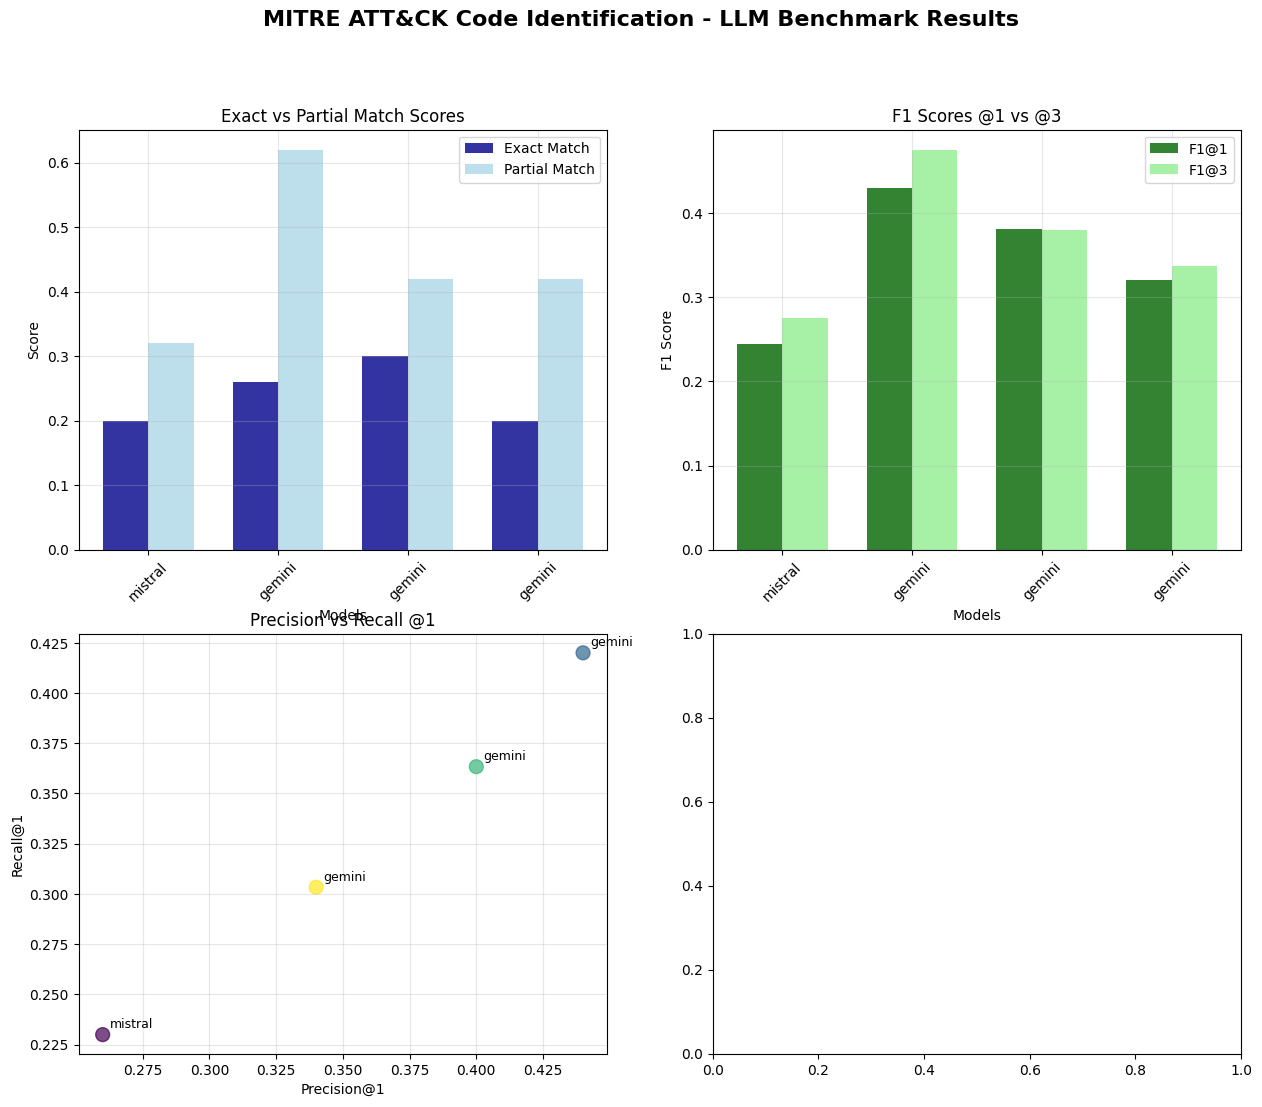

In [36]:
results_df = pd.read_csv("benchmark_results.csv", index_col=0)
results_dict = results_df.to_dict(orient="index")

visualize_results(results_dict)

## Error Analysis and Model Insights

This section provides detailed error analysis to understand model performance patterns and weaknesses.

In [ ]:
# Error Analysis Function
def analyze_prediction_errors(test_data: pd.DataFrame, predictions_dict: Dict[str, List[List[str]]], max_examples: int = 10):
    """Analyze prediction errors to understand model weaknesses"""

    print("Error Analysis Summary")
    print("=" * 50)

    for model_name, predictions in predictions_dict.items():
        print(f"\nModel: {model_name}")
        print("-" * 30)

        y_true = test_data['labels_parsed'].tolist()[:len(predictions)]

        # Find examples with different types of errors
        exact_matches = []
        partial_matches = []
        complete_misses = []

        for i, (true_labels, pred_labels) in enumerate(zip(y_true, predictions)):
            true_set = set(true_labels)
            pred_set = set(pred_labels)

            if true_set == pred_set:
                exact_matches.append(i)
            elif true_set & pred_set:  # Some overlap
                partial_matches.append(i)
            else:
                complete_misses.append(i)

        print(f"Exact matches: {len(exact_matches)}")
        print(f"Partial matches: {len(partial_matches)}")
        print(f"Complete misses: {len(complete_misses)}")

        # Show examples of each type
        print(f"\nExample complete misses (showing up to {min(3, len(complete_misses))}):")
        for idx in complete_misses[:3]:
            text = test_data.iloc[idx]['text1'][:100] + "..."
            true_labels = y_true[idx]
            pred_labels = predictions[idx]
            print(f"  Text: {text}")
            print(f"  True: {true_labels}")
            print(f"  Pred: {pred_labels}")
            print()

print("Error analysis function defined!")

In [ ]:
# Demo Error Analysis Function
def demo_error_analysis():
    """Demonstrate error analysis with sample data"""
    print("Demo Error Analysis")
    print("=" * 40)
    print("In actual implementation, this would show:")
    print("• Most commonly missed MITRE codes")
    print("• Types of descriptions that are hardest to classify")
    print("• Confusion between similar techniques")
    print("• Model-specific strengths and weaknesses")
    print("\nExample insights:")
    print("- Models struggle with multi-technique descriptions")
    print("- Sub-technique identification is challenging")
    print("- Some models over-predict common techniques like T1059")

print("Demo error analysis function defined!")

In [ ]:
# Execute: Run Demo Error Analysis
demo_error_analysis()

## Conclusion and Next Steps

### Summary

This notebook provides a comprehensive framework for benchmarking LLM models on MITRE ATT&CK code identification:

1. **Dataset Creation**: Successfully created a balanced test dataset by sampling from multiple TSV files
2. **Model Setup**: Configured infrastructure to test multiple Groq LLM models
3. **Evaluation Framework**: Implemented comprehensive metrics including exact match, partial match, precision@k, recall@k, and F1@k
4. **Visualization**: Created detailed charts to compare model performance
5. **Error Analysis**: Provided tools to understand model weaknesses and strengths

### Key Metrics Explained

- **Exact Match**: Percentage of samples where predicted codes exactly match ground truth
- **Partial Match**: Percentage of samples with at least one correct code prediction
- **Precision@k**: Accuracy of top-k predictions
- **Recall@k**: Coverage of ground truth in top-k predictions
- **F1@k**: Harmonic mean of precision and recall at k

### Next Steps

1. **Set up Groq API**: Replace the placeholder API key with your actual Groq API key
2. **Run Full Benchmark**: Execute benchmarking on all models with larger sample sizes
3. **Experiment with Prompts**: Try different prompt engineering techniques
4. **Fine-tuning**: Consider fine-tuning models on domain-specific data
5. **Ensemble Methods**: Combine predictions from multiple models
6. **Real-world Testing**: Test on fresh, unlabeled threat intelligence data

### Usage Instructions

1. Run all cells up to the dataset creation section
2. Add your Groq API key in the configuration
3. Uncomment and run the actual benchmarking section
4. Analyze results and visualizations
5. Use insights to improve model selection and deployment strategies